<a href="https://colab.research.google.com/github/mdsahil28/Retail-Sales-EDA-Project/blob/main/Sales_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train.csv.zip')

df.head()




,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [ ]:
print("Shape of data:", df.shape)

print("\nData Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


Shape of data: (9800, 18)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales         

In [ ]:
df['Postal Code'] = df['Postal Code'].fillna(0)

df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month_name()
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

print("Duplicates:", df.duplicated().sum())
print("Missing values now:\n", df.isnull().sum().sum())
df[['Order Date', 'Order Year', 'Order Month', 'Shipping Days', 'Sales']].head()


Duplicates: 0
Missing values now:
 0


,Order Date,Order Year,Order Month,Shipping Days,Sales
0,2017-11-08,2017,November,3,261.9600
1,2017-11-08,2017,November,3,731.9400
2,2017-06-12,2017,June,4,14.6200
3,2016-10-11,2016,October,7,957.5775
4,2016-10-11,2016,October,7,22.3680


/tmp/ipykernel_724/1003828576.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_sales.index, y=cat_sales.values, palette='viridis')
/tmp/ipykernel_724/1003828576.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=reg_sales.index, y=reg_sales.values, palette='magma')
/tmp/ipykernel_724/1003828576.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sub_sales.index, y=sub_sales.values, palette='coolwarm')


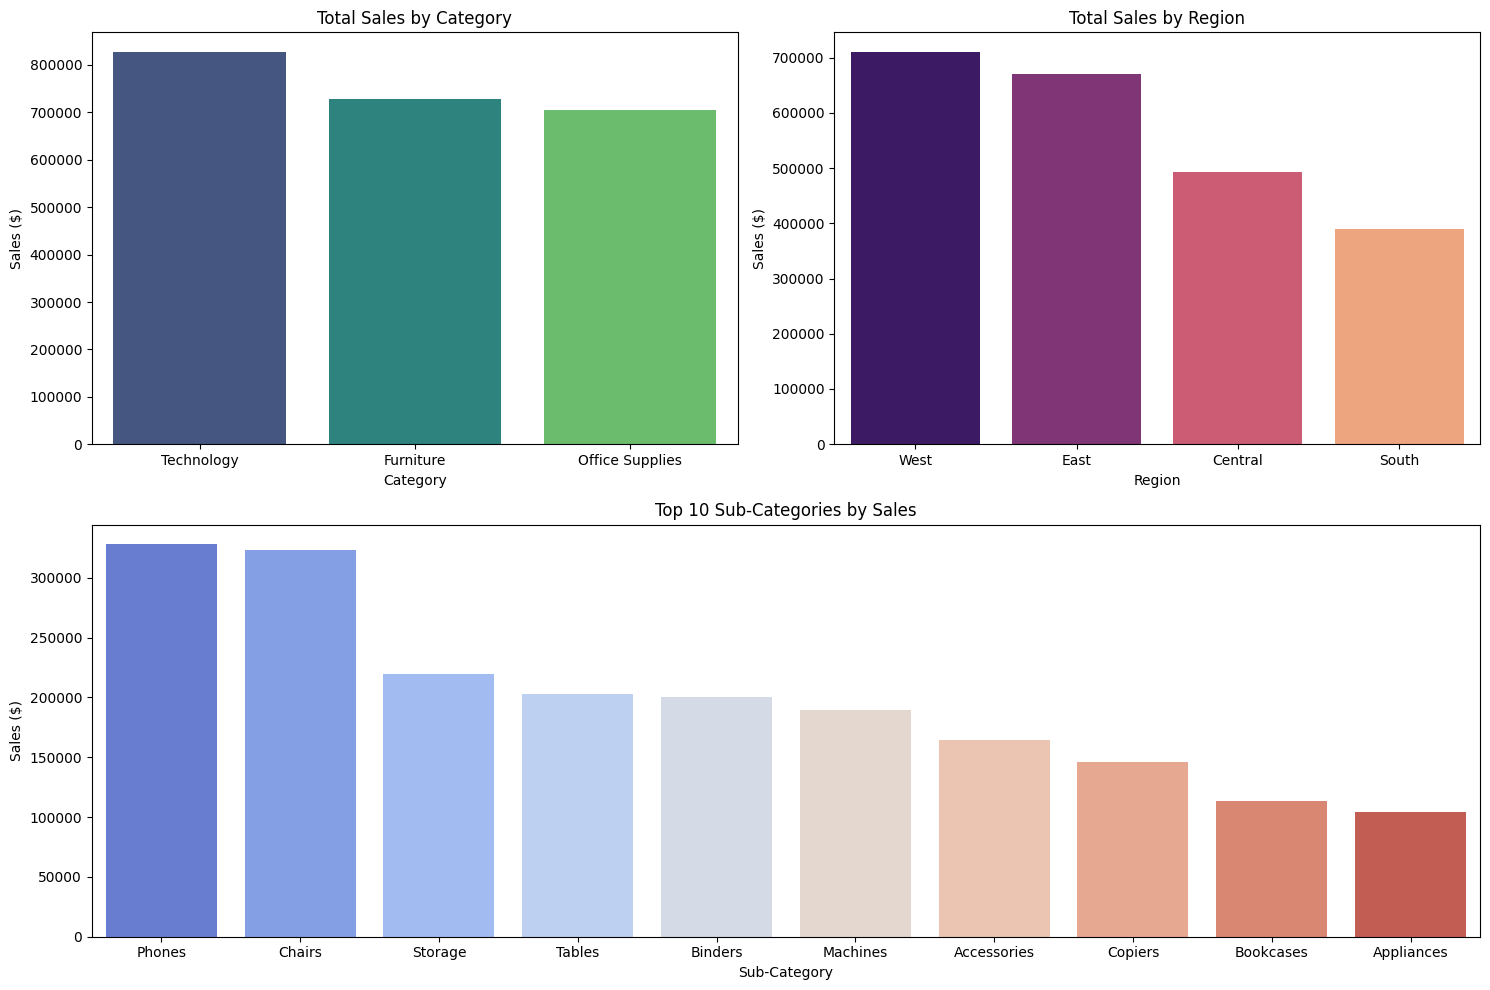

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
cat_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
sns.barplot(x=cat_sales.index, y=cat_sales.values, palette='viridis')
plt.title('Total Sales by Category')
plt.ylabel('Sales ($)')

plt.subplot(2, 2, 2)
reg_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
sns.barplot(x=reg_sales.index, y=reg_sales.values, palette='magma')
plt.title('Total Sales by Region')
plt.ylabel('Sales ($)')

plt.subplot(2, 1, 2)
sub_sales = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=sub_sales.index, y=sub_sales.values, palette='coolwarm')
plt.title('Top 10 Sub-Categories by Sales')
plt.ylabel('Sales ($)')

plt.tight_layout()
plt.show()


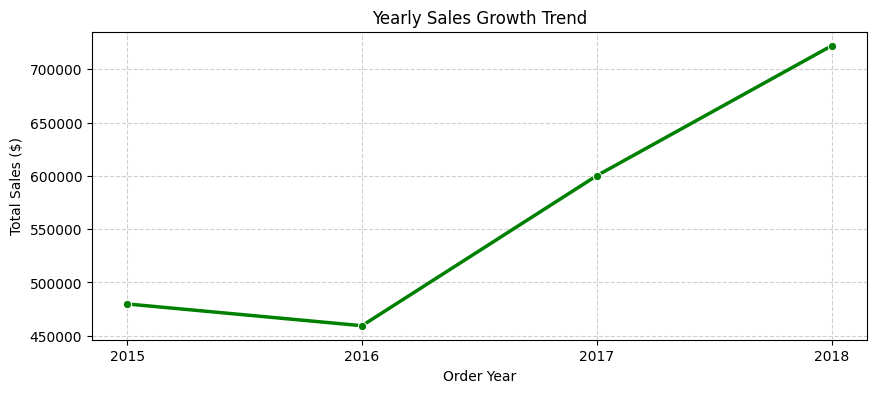

--- KEY BUSINESS INSIGHTS ---
1. Total Revenue: $2,261,536.78
2. Average Shipping Time: 4.0 days
3. Top Category: Technology
4. Top Region: West
5. Top 3 Cities by Sales:
City
New York City    252462.547
Los Angeles      173420.181
Seattle          116106.322
Name: Sales, dtype: float64


In [ ]:
plt.figure(figsize=(10, 4))
yearly_sales = df.groupby('Order Year')['Sales'].sum()
sns.lineplot(x=yearly_sales.index, y=yearly_sales.values, marker='o', linewidth=2.5, color='green')
plt.title('Yearly Sales Growth Trend')
plt.xticks(yearly_sales.index)
plt.ylabel('Total Sales ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("--- KEY BUSINESS INSIGHTS ---")
print(f"1. Total Revenue: ${df['Sales'].sum():,.2f}")
print(f"2. Average Shipping Time: {df['Shipping Days'].mean():.1f} days")
print(f"3. Top Category: {df.groupby('Category')['Sales'].sum().idxmax()}")
print(f"4. Top Region: {df.groupby('Region')['Sales'].sum().idxmax()}")
print(f"5. Top 3 Cities by Sales:\n{df.groupby('City')['Sales'].sum().sort_values(ascending=False).head(3)}")
